In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

file_name = "raw_data/chunk2.hdf5"
csv_file = "raw_data/chunk2.csv"

# Load index metadata
df = pd.read_csv(csv_file)
df.head()

C:\Users\andre\AppData\Local\Temp\ipykernel_10012\3888635804.py:8: DtypeWarning: Columns (26: source_mechanism_strike_dip_rake) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_file)


,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_magnitude_author,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name
0,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.5,17.080000,...,NaN,NaN,0.92,102.09,159.3,[56.79999924 55.40000153 47.40000153],[[2896.]],2006-07-23 15:59:00.960000,earthquake_local,109C.TA_20060723155859_EV
1,TA,109C,BH,32.8889,-117.1051,150.0,600.0,manual,0.5,16.879999,...,NaN,NaN,0.91,101.34,281.7,[65. 65.5 61.40000153],[[5508.]],2006-11-03 15:56:53.610000,earthquake_local,109C.TA_20061103155652_EV
2,TA,109C,BH,32.8889,-117.1051,150.0,500.0,manual,0.5,17.260000,...,NaN,NaN,0.92,101.87,280.5,[37.20000076 42. 38.59999847],[[3114.]],2006-11-03 16:12:24.700000,earthquake_local,109C.TA_20061103161223_EV
3,TA,109C,BH,32.8889,-117.1051,150.0,900.0,manual,0.5,17.280001,...,NaN,NaN,0.93,103.26,281.6,[54.09999847 54.90000153 45.5 ],[[3152.]],2006-11-14 13:32:22.540000,earthquake_local,109C.TA_20061114133221_EV
4,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.5,18.139999,...,NaN,NaN,0.92,102.48,4.7,[58.20000076 56.20000076 53.79999924],[[3134.]],2006-11-27 10:46:41.060000,earthquake_local,109C.TA_20061127104640_EV


In [2]:
df.columns

Index(['network_code', 'receiver_code', 'receiver_type', 'receiver_latitude',
       'receiver_longitude', 'receiver_elevation_m', 'p_arrival_sample',
       'p_status', 'p_weight', 'p_travel_sec', 's_arrival_sample', 's_status',
       's_weight', 'source_id', 'source_origin_time',
       'source_origin_uncertainty_sec', 'source_latitude', 'source_longitude',
       'source_error_sec', 'source_gap_deg',
       'source_horizontal_uncertainty_km', 'source_depth_km',
       'source_depth_uncertainty_km', 'source_magnitude',
       'source_magnitude_type', 'source_magnitude_author',
       'source_mechanism_strike_dip_rake', 'source_distance_deg',
       'source_distance_km', 'back_azimuth_deg', 'snr_db', 'coda_end_sample',
       'trace_start_time', 'trace_category', 'trace_name'],
      dtype='str')

In [3]:
import re

df_eq = df[df["trace_category"] == "earthquake_local"]
temp = df["snr_db"][0]
temp.split("[")[1].split("]")[0].split(" ")
# def process(x):
#     processed = re.findall(r"\d+.\d*", x)
#     return processed
df_eq = df_eq[df_eq["snr_db"].apply(lambda s: min(map(float, re.findall(r"\d+.\d*", s)))) >= 10.0]
print(len(df_eq))
df_eq.head()

181395


,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_magnitude_author,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name
0,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.5,17.080000,...,NaN,NaN,0.92,102.09,159.3,[56.79999924 55.40000153 47.40000153],[[2896.]],2006-07-23 15:59:00.960000,earthquake_local,109C.TA_20060723155859_EV
1,TA,109C,BH,32.8889,-117.1051,150.0,600.0,manual,0.5,16.879999,...,NaN,NaN,0.91,101.34,281.7,[65. 65.5 61.40000153],[[5508.]],2006-11-03 15:56:53.610000,earthquake_local,109C.TA_20061103155652_EV
2,TA,109C,BH,32.8889,-117.1051,150.0,500.0,manual,0.5,17.260000,...,NaN,NaN,0.92,101.87,280.5,[37.20000076 42. 38.59999847],[[3114.]],2006-11-03 16:12:24.700000,earthquake_local,109C.TA_20061103161223_EV
3,TA,109C,BH,32.8889,-117.1051,150.0,900.0,manual,0.5,17.280001,...,NaN,NaN,0.93,103.26,281.6,[54.09999847 54.90000153 45.5 ],[[3152.]],2006-11-14 13:32:22.540000,earthquake_local,109C.TA_20061114133221_EV
4,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.5,18.139999,...,NaN,NaN,0.92,102.48,4.7,[58.20000076 56.20000076 53.79999924],[[3134.]],2006-11-27 10:46:41.060000,earthquake_local,109C.TA_20061127104640_EV


In [4]:
event_counts = df_eq.groupby("source_id").size()
valid_events = event_counts[event_counts >= 5].index
filtered_df_eq = df_eq[df_eq["source_id"].isin(valid_events)]
filtered_df_eq.head()

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_magnitude_author,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name
26,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.53,17.620001,...,CI,NaN,0.9618,106.96,68.7,[17.79999924 20.79999924 21.29999924],[[3100.]],2007-06-10 11:51:24.070000,earthquake_local,109C.TA_20070610115123_EV
31,TA,109C,BH,32.8889,-117.1051,150.0,800.0,manual,0.64,7.560000,...,CI,NaN,0.3866,42.99,104.3,[32.40000153 35.59999847 34.5 ],[[1860.]],2007-06-17 20:31:08.270000,earthquake_local,109C.TA_20070617203107_EV
53,TA,109C,BH,32.8889,-117.1051,150.0,800.0,manual,0.69,10.980000,...,CI,NaN,0.5995,66.67,17.9,[35.59999847 37.5 35.20000076],[[2119.]],2007-08-17 06:28:01.810000,earthquake_local,109C.TA_20070817062800_EV
56,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.61,9.260000,...,CI,NaN,0.4922,54.74,34.9,[27.79999924 29.60000038 30.60000038],[[1954.]],2007-08-25 05:02:53.070000,earthquake_local,109C.TA_20070825050252_EV
64,TA,109C,BH,32.8889,-117.1051,150.0,500.0,manual,0.56,16.670000,...,CI,NaN,0.9115,101.36,77.3,[10.19999981 21.5 14.39999962],[[3199.]],2007-09-04 03:52:31.870000,earthquake_local,109C.TA_20070904035230_EV


In [9]:
# Convert trace_start_times into dates using strptime
from datetime import datetime
filtered_df_eq["trace_start_time"] = pd.to_datetime(filtered_df_eq["trace_start_time"], format='mixed')
filtered_df_eq

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_magnitude_author,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name
26,TA,109C,BH,32.8889,-117.105100,150.0,700.0,manual,0.53,17.620001,...,CI,NaN,0.96180,106.96,68.7,[17.79999924 20.79999924 21.29999924],[[3100.]],2007-06-10 11:51:24.070,earthquake_local,109C.TA_20070610115123_EV
31,TA,109C,BH,32.8889,-117.105100,150.0,800.0,manual,0.64,7.560000,...,CI,NaN,0.38660,42.99,104.3,[32.40000153 35.59999847 34.5 ],[[1860.]],2007-06-17 20:31:08.270,earthquake_local,109C.TA_20070617203107_EV
53,TA,109C,BH,32.8889,-117.105100,150.0,800.0,manual,0.69,10.980000,...,CI,NaN,0.59950,66.67,17.9,[35.59999847 37.5 35.20000076],[[2119.]],2007-08-17 06:28:01.810,earthquake_local,109C.TA_20070817062800_EV
56,TA,109C,BH,32.8889,-117.105100,150.0,700.0,manual,0.61,9.260000,...,CI,NaN,0.49220,54.74,34.9,[27.79999924 29.60000038 30.60000038],[[1954.]],2007-08-25 05:02:53.070,earthquake_local,109C.TA_20070825050252_EV
64,TA,109C,BH,32.8889,-117.105100,150.0,500.0,manual,0.56,16.670000,...,CI,NaN,0.91150,101.36,77.3,[10.19999981 21.5 14.39999962],[[3199.]],2007-09-04 03:52:31.870,earthquake_local,109C.TA_20070904035230_EV
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199954,PB,B087,EH,33.4955,-116.602667,1139.0,900.0,manual,0.62,8.280000,...,CI,NaN,0.43120,48.15,346.8,[32.59999847 30.70000076 30.29999924],[[2398.]],2011-10-30 03:43:41.820,earthquake_local,B087.PB_20111030034340_EV
199956,PB,B087,EH,33.4955,-116.602667,1139.0,400.0,autopicker,0.94,2.120000,...,CI,NaN,0.03727,4.14,131.1,[50.70000076 47.90000153 45.70000076],[[1022.]],2011-10-30 16:28:49.360,earthquake_local,B087.PB_20111030162848_EV
199957,PB,B087,EH,33.4955,-116.602667,1139.0,899.0,autopicker,0.93,2.490000,...,CI,NaN,0.05173,5.75,98.9,[19.79999924 22.20000076 19.60000038],[[1488.]],2011-10-30 18:01:28.160,earthquake_local,B087.PB_20111030180127_EV
199975,PB,B087,EH,33.4955,-116.602667,1139.0,900.0,manual,0.65,1.480000,...,CI,NaN,0.02427,2.70,77.3,[32.70000076 31.20000076 31.20000076],[[2236.]],2011-11-01 07:52:56.440,earthquake_local,B087.PB_20111101075255_EV


In [10]:
import numpy as np

def geodetic_to_ecef(lat, lon, elevation_m=0.0):
    """
    Converts Latitude, Longitude, Elevation to 3D ECEF Cartesian coordinates (in km).
    """
    a = 6378137.0  # WGS-84 Earth semi-major axis (meters)
    e_sq = 0.00669437999014  # WGS-84 eccentricity squared
    
    lat_rad = np.radians(lat)
    lon_rad = np.radians(lon)
    
    N = a / np.sqrt(1 - e_sq * np.sin(lat_rad)**2)
    
    x = (N + elevation_m) * np.cos(lat_rad) * np.cos(lon_rad)
    y = (N + elevation_m) * np.cos(lat_rad) * np.sin(lon_rad)
    z = (N * (1 - e_sq) + elevation_m) * np.sin(lat_rad)
    
    return np.array([x, y, z], dtype=np.float32) / 1000.0  # Shape: (3,)

def process_row_coords(row):
    return geodetic_to_ecef(
        lat=row["receiver_latitude"],
        lon=row["receiver_longitude"],
        elevation_m=row["receiver_elevation_m"]
    )

# Assign 3D coordinate vector [x, y, z] to a new column
filtered_df_eq["station_coords_ecef"] = filtered_df_eq.apply(process_row_coords, axis=1)
filtered_df_eq.head()

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_mechanism_strike_dip_rake,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name,station_coords_ecef
26,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.53,17.620001,...,NaN,0.9618,106.96,68.7,[17.79999924 20.79999924 21.29999924],[[3100.]],2007-06-10 11:51:24.070,earthquake_local,109C.TA_20070610115123_EV,"[-2442.7385, -4772.482, 3443.7]"
31,TA,109C,BH,32.8889,-117.1051,150.0,800.0,manual,0.64,7.560000,...,NaN,0.3866,42.99,104.3,[32.40000153 35.59999847 34.5 ],[[1860.]],2007-06-17 20:31:08.270,earthquake_local,109C.TA_20070617203107_EV,"[-2442.7385, -4772.482, 3443.7]"
53,TA,109C,BH,32.8889,-117.1051,150.0,800.0,manual,0.69,10.980000,...,NaN,0.5995,66.67,17.9,[35.59999847 37.5 35.20000076],[[2119.]],2007-08-17 06:28:01.810,earthquake_local,109C.TA_20070817062800_EV,"[-2442.7385, -4772.482, 3443.7]"
56,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.61,9.260000,...,NaN,0.4922,54.74,34.9,[27.79999924 29.60000038 30.60000038],[[1954.]],2007-08-25 05:02:53.070,earthquake_local,109C.TA_20070825050252_EV,"[-2442.7385, -4772.482, 3443.7]"
64,TA,109C,BH,32.8889,-117.1051,150.0,500.0,manual,0.56,16.670000,...,NaN,0.9115,101.36,77.3,[10.19999981 21.5 14.39999962],[[3199.]],2007-09-04 03:52:31.870,earthquake_local,109C.TA_20070904035230_EV,"[-2442.7385, -4772.482, 3443.7]"


In [11]:
import h5py
import obspy
from obspy import UTCDateTime
import numpy as np

def process_stead_trace(hdf5_file, trace_name):
    dataset = hdf5_file.get(f"data/{trace_name}")
    raw_data = np.array(dataset, dtype=np.float32) # (6000, 3) -> E, N, Z
    
    stream = obspy.Stream()
    for ch_idx, comp in enumerate(['E', 'N', 'Z']):
        tr = obspy.Trace(data=raw_data[:, ch_idx])
        tr.stats.starttime = UTCDateTime(dataset.attrs['trace_start_time'])
        tr.stats.delta = 0.01  # 100 Hz sampling rate
        tr.stats.channel = dataset.attrs['receiver_type'] + comp
        stream.append(tr)
        
    # Detrend and bandpass filter
    stream.detrend("demean")
    stream.detrend("linear")
    stream.filter("bandpass", freqmin=0.5, freqmax=20.0)
    
    return np.stack([tr.data for tr in stream], axis=-1)  # (6000, 3)

In [12]:
from tqdm import tqdm
dtf2 = h5py.File(file_name, 'r')

processed_waves = []
for i, row in tqdm(filtered_df_eq.iterrows()):
    processed_wave = process_stead_trace(dtf2, row["trace_name"])
    processed_waves.append(processed_wave)
filtered_df_eq["processed_waves"] = processed_waves
filtered_df_eq.head()

5968it [00:58, 102.84it/s]


,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name,station_coords_ecef,processed_waves
26,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.53,17.620001,...,0.9618,106.96,68.7,[17.79999924 20.79999924 21.29999924],[[3100.]],2007-06-10 11:51:24.070,earthquake_local,109C.TA_20070610115123_EV,"[-2442.7385, -4772.482, 3443.7]","[[-0.0023108322892126673, -0.00496088310572293..."
31,TA,109C,BH,32.8889,-117.1051,150.0,800.0,manual,0.64,7.560000,...,0.3866,42.99,104.3,[32.40000153 35.59999847 34.5 ],[[1860.]],2007-06-17 20:31:08.270,earthquake_local,109C.TA_20070617203107_EV,"[-2442.7385, -4772.482, 3443.7]","[[0.0014642053630435589, -0.002707721448555072..."
53,TA,109C,BH,32.8889,-117.1051,150.0,800.0,manual,0.69,10.980000,...,0.5995,66.67,17.9,[35.59999847 37.5 35.20000076],[[2119.]],2007-08-17 06:28:01.810,earthquake_local,109C.TA_20070817062800_EV,"[-2442.7385, -4772.482, 3443.7]","[[-0.0023866203934659303, 0.000262032976202966..."
56,TA,109C,BH,32.8889,-117.1051,150.0,700.0,manual,0.61,9.260000,...,0.4922,54.74,34.9,[27.79999924 29.60000038 30.60000038],[[1954.]],2007-08-25 05:02:53.070,earthquake_local,109C.TA_20070825050252_EV,"[-2442.7385, -4772.482, 3443.7]","[[-0.004033673602420107, -0.006879100270052335..."
64,TA,109C,BH,32.8889,-117.1051,150.0,500.0,manual,0.56,16.670000,...,0.9115,101.36,77.3,[10.19999981 21.5 14.39999962],[[3199.]],2007-09-04 03:52:31.870,earthquake_local,109C.TA_20070904035230_EV,"[-2442.7385, -4772.482, 3443.7]","[[0.003691818123047461, 0.0036512332168670927,..."


In [13]:
grouped_filtered_df_eq = filtered_df_eq.groupby("source_id").agg(list)
grouped_filtered_df_eq.head()

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name,station_coords_ecef,processed_waves
source_id,,,,,,,,,,,,,,,,,,,,,
11688339,"[TA, TA, TA, TA, TA]","[A06A, A07A, B05A, B06A, B07A]","[BH, BH, BH, BH, BH]","[49.0983, 49.048, 48.2641, 48.5183, 48.4607]","[-121.4804, -120.3837, -122.096, -121.4845, -1...","[576.0, 1842.0, 154.5, 75.0, 781.0]","[500.0, 600.0, 600.0, 400.0, 600.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[15.15999984741211, 12.039999961853027, 17.920...",...,"[0.81, 0.61, 0.95, 0.52, 0.39]","[89.42, 67.49, 105.87, 57.85, 43.25]","[320.6, 20.3, 257.5, 274.6, 92.5]","[[39.70000076 41.40000153 39.59999847], [55.5 ...","[[[3199.]], [[2048.]], [[2957.]], [[2646.]], [...","[2007-03-01 10:23:54.190000, 2007-03-01 10:23:...","[earthquake_local, earthquake_local, earthquak...","[A06A.TA_20070301102353_EV, A07A.TA_2007030110...","[[-2185.2036, -3568.6677, 4798.159], [-2119.05...","[[[-0.004969728476491002, -0.00517578076381474..."
12963489,"[TA, TA, TA, TA, TA]","[A04A, A05A, B04A, B05A, B06A]","[BH, BH, BH, BH, BH]","[48.7197, 48.9983, 48.0575, 48.2641, 48.5183]","[-122.707, -122.0852, -123.504, -122.096, -121...","[23.0, 174.3, 293.8, 154.5, 75.0]","[800.0, 500.0, 600.0, 800.0, 900.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[9.460000038146973, 14.649999618530272, 12.060...",...,"[0.29, 0.76, 0.58, 0.54, 0.92]","[32.83, 84.15, 64.11, 60.16, 102.19]","[20.3, 42.5, 228.3, 109.0, 84.8]","[[44.70000076 45.40000153 39.79999924], [56.29...","[[[2187.]], [[2926.]], [[3053.]], [[2543.]], [...","[2007-09-13 04:21:37.020000, 2007-09-13 04:21:...","[earthquake_local, earthquake_local, earthquak...","[A04A.TA_20070913042136_EV, A05A.TA_2007091304...","[[-2278.0461, -3547.4683, 4770.0684], [-2227.0...","[[[0.08128437609078558, 0.007397979778873907, ..."
16869011,"[HT, HT, HT, HL, HL]","[AGG, AGG, AGG, ATH, ATH]","[HH, HH, HH, HH, HH]","[39.0211, 39.0211, 39.0211, 37.97384, 37.97384]","[22.336, 22.336, 22.336, 23.71767, 23.71767]","[625.0, 625.0, 625.0, 93.0, 93.0]","[800.0, 700.0, 600.0, 600.0, 400.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[16.3700008392334, 16.3700008392334, 16.370000...",...,"[0.9, 0.9, 0.9, 0.82, 0.82]","[99.13, 99.13, 99.13, 91.44, 91.44]","[286.9, 286.9, 286.9, 164.1, 164.1]","[[29.79999924 35.90000153 26.79999924], [29.39...","[[[5121.]], [[5900.]], [[5900.]], [[5082.]], [...","[2011-01-17 22:27:19.300000, 2011-01-17 22:27:...","[earthquake_local, earthquake_local, earthquak...","[AGG.HT_20110117222718_EV, AGG.HT_201101172227...","[[4590.0195, 1885.8743, 3994.5308], [4590.0195...","[[[0.44272592192145555, -1.002307463600426, -1..."
17386887,"[AV, AV, AV, AV, AV, AT, AT]","[AKGG, AKGG, AKLV, AKLV, AKRB, AKUT, AKUT]","[BH, BH, BH, BH, BH, BH, BH]","[54.1979, 54.1979, 54.1618, 54.1618, 54.1292, ...","[-165.9936, -165.9936, -165.9576, -165.9576, -...","[326.0, 326.0, 551.0, 551.0, 334.0, 19.2, 19.2]","[700.0, 400.0, 800.0, 400.0, 400.0, 900.0, 800.0]","[manual, manual, manual, manual, manual, manua...","[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]","[17.8700008392334, 17.8700008392334, 16.829999...",...,"[0.84, 0.84, 0.8, 0.8, 0.82, 0.71, 0.71]","[93.67, 93.67, 89.07, 89.07, 91.34, 79.42, 79.42]","[321.7, 321.7, 321.2, 321.2, 316.2, 326.5, 326.5]","[[22.39999962 25.10000038 27. ], [25.29...","[[[5900.]], [[5664.]], [[5136.]], [[5404.]], [...","[2011-09-07 18:20:10.040000, 2011-09-07 18:20:...","[earthquake_local, earthquake_local, earthquak...","[AKGG.AV_20110907182009_EV, AKGG.AV_2011090718...","[[-3628.3809, -905.0874, 5149.925], [-3628.380...","[[[481.2153165171389, 172.23938019046915, -6.6..."
1775,"[X2, X2, X2, X2, X2, X2, X2, X2]","[258, 262, 263, 264, 265, 266, 268, 270]","[BH, BH, BH, BH, BH, BH, BH, B

In [14]:
def valid_time_span(times, max_span_sec=60):
    return (max(times) - min(times)).total_seconds() <= max_span_sec

valid_events_mask = grouped_filtered_df_eq["trace_start_time"].apply(valid_time_span)
grouped_clean = grouped_filtered_df_eq[valid_events_mask].copy()
grouped_filtered_df_eq = grouped_clean
grouped_filtered_df_eq.head()

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,source_distance_deg,source_distance_km,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name,station_coords_ecef,processed_waves
source_id,,,,,,,,,,,,,,,,,,,,,
11688339,"[TA, TA, TA, TA, TA]","[A06A, A07A, B05A, B06A, B07A]","[BH, BH, BH, BH, BH]","[49.0983, 49.048, 48.2641, 48.5183, 48.4607]","[-121.4804, -120.3837, -122.096, -121.4845, -1...","[576.0, 1842.0, 154.5, 75.0, 781.0]","[500.0, 600.0, 600.0, 400.0, 600.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[15.15999984741211, 12.039999961853027, 17.920...",...,"[0.81, 0.61, 0.95, 0.52, 0.39]","[89.42, 67.49, 105.87, 57.85, 43.25]","[320.6, 20.3, 257.5, 274.6, 92.5]","[[39.70000076 41.40000153 39.59999847], [55.5 ...","[[[3199.]], [[2048.]], [[2957.]], [[2646.]], [...","[2007-03-01 10:23:54.190000, 2007-03-01 10:23:...","[earthquake_local, earthquake_local, earthquak...","[A06A.TA_20070301102353_EV, A07A.TA_2007030110...","[[-2185.2036, -3568.6677, 4798.159], [-2119.05...","[[[-0.004969728476491002, -0.00517578076381474..."
12963489,"[TA, TA, TA, TA, TA]","[A04A, A05A, B04A, B05A, B06A]","[BH, BH, BH, BH, BH]","[48.7197, 48.9983, 48.0575, 48.2641, 48.5183]","[-122.707, -122.0852, -123.504, -122.096, -121...","[23.0, 174.3, 293.8, 154.5, 75.0]","[800.0, 500.0, 600.0, 800.0, 900.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[9.460000038146973, 14.649999618530272, 12.060...",...,"[0.29, 0.76, 0.58, 0.54, 0.92]","[32.83, 84.15, 64.11, 60.16, 102.19]","[20.3, 42.5, 228.3, 109.0, 84.8]","[[44.70000076 45.40000153 39.79999924], [56.29...","[[[2187.]], [[2926.]], [[3053.]], [[2543.]], [...","[2007-09-13 04:21:37.020000, 2007-09-13 04:21:...","[earthquake_local, earthquake_local, earthquak...","[A04A.TA_20070913042136_EV, A05A.TA_2007091304...","[[-2278.0461, -3547.4683, 4770.0684], [-2227.0...","[[[0.08128437609078558, 0.007397979778873907, ..."
16869011,"[HT, HT, HT, HL, HL]","[AGG, AGG, AGG, ATH, ATH]","[HH, HH, HH, HH, HH]","[39.0211, 39.0211, 39.0211, 37.97384, 37.97384]","[22.336, 22.336, 22.336, 23.71767, 23.71767]","[625.0, 625.0, 625.0, 93.0, 93.0]","[800.0, 700.0, 600.0, 600.0, 400.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[16.3700008392334, 16.3700008392334, 16.370000...",...,"[0.9, 0.9, 0.9, 0.82, 0.82]","[99.13, 99.13, 99.13, 91.44, 91.44]","[286.9, 286.9, 286.9, 164.1, 164.1]","[[29.79999924 35.90000153 26.79999924], [29.39...","[[[5121.]], [[5900.]], [[5900.]], [[5082.]], [...","[2011-01-17 22:27:19.300000, 2011-01-17 22:27:...","[earthquake_local, earthquake_local, earthquak...","[AGG.HT_20110117222718_EV, AGG.HT_201101172227...","[[4590.0195, 1885.8743, 3994.5308], [4590.0195...","[[[0.44272592192145555, -1.002307463600426, -1..."
17386887,"[AV, AV, AV, AV, AV, AT, AT]","[AKGG, AKGG, AKLV, AKLV, AKRB, AKUT, AKUT]","[BH, BH, BH, BH, BH, BH, BH]","[54.1979, 54.1979, 54.1618, 54.1618, 54.1292, ...","[-165.9936, -165.9936, -165.9576, -165.9576, -...","[326.0, 326.0, 551.0, 551.0, 334.0, 19.2, 19.2]","[700.0, 400.0, 800.0, 400.0, 400.0, 900.0, 800.0]","[manual, manual, manual, manual, manual, manua...","[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]","[17.8700008392334, 17.8700008392334, 16.829999...",...,"[0.84, 0.84, 0.8, 0.8, 0.82, 0.71, 0.71]","[93.67, 93.67, 89.07, 89.07, 91.34, 79.42, 79.42]","[321.7, 321.7, 321.2, 321.2, 316.2, 326.5, 326.5]","[[22.39999962 25.10000038 27. ], [25.29...","[[[5900.]], [[5664.]], [[5136.]], [[5404.]], [...","[2011-09-07 18:20:10.040000, 2011-09-07 18:20:...","[earthquake_local, earthquake_local, earthquak...","[AKGG.AV_20110907182009_EV, AKGG.AV_2011090718...","[[-3628.3809, -905.0874, 5149.925], [-3628.380...","[[[481.2153165171389, 172.23938019046915, -6.6..."
1775,"[X2, X2, X2, X2, X2, X2, X2, X2]","[258, 262, 263, 264, 265, 266, 268, 270]","[BH, BH, BH, BH, BH, BH, BH, B

In [15]:
sample_trace_name = grouped_filtered_df_eq.iloc[0]["trace_name"][0]
dtf2 = h5py.File(file_name, 'r')
waves = process_stead_trace(dtf2, sample_trace_name)
waves

array([[-4.96972848e-03, -5.17578076e-03,  4.47348684e-03],
       [-2.80595966e-02, -2.96014852e-02,  2.55240635e-02],
       [-6.84452407e-02, -7.40751801e-02,  6.35689103e-02],
       ...,
       [-2.24178361e+00, -7.67099727e+00, -2.01653455e+00],
       [-2.04583297e+00, -7.24610601e+00, -1.87853524e+00],
       [-1.78964095e+00, -6.99348078e+00, -1.71707101e+00]],
      shape=(6000, 3))

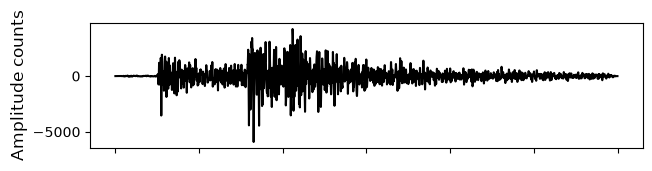

In [16]:
fig = plt.figure()
ax = fig.add_subplot(311)         
plt.plot(waves[:,0], 'k')
plt.rcParams["figure.figsize"] = (8, 5)
legend_properties = {'weight':'bold'}    
plt.tight_layout()
ymin, ymax = ax.get_ylim()      
plt.ylabel('Amplitude counts', fontsize=12) 
ax.set_xticklabels([]);

In [17]:
min_start_times = []
for i, row in grouped_filtered_df_eq.iterrows():
    min_start_time = min(row["trace_start_time"])
    min_start_times.append(min_start_time)
grouped_filtered_df_eq["min_start_time"] = min_start_times

relative_times = []
for i, row in grouped_filtered_df_eq.iterrows():
    relative_time_i = []
    for start_time in row["trace_start_time"]:
        relative_time_i.append(start_time - row["min_start_time"])
    relative_times.append(relative_time_i)
grouped_filtered_df_eq["relative_time"] = relative_times
grouped_filtered_df_eq.head()

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,back_azimuth_deg,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name,station_coords_ecef,processed_waves,min_start_time,relative_time
source_id,,,,,,,,,,,,,,,,,,,,,
11688339,"[TA, TA, TA, TA, TA]","[A06A, A07A, B05A, B06A, B07A]","[BH, BH, BH, BH, BH]","[49.0983, 49.048, 48.2641, 48.5183, 48.4607]","[-121.4804, -120.3837, -122.096, -121.4845, -1...","[576.0, 1842.0, 154.5, 75.0, 781.0]","[500.0, 600.0, 600.0, 400.0, 600.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[15.15999984741211, 12.039999961853027, 17.920...",...,"[320.6, 20.3, 257.5, 274.6, 92.5]","[[39.70000076 41.40000153 39.59999847], [55.5 ...","[[[3199.]], [[2048.]], [[2957.]], [[2646.]], [...","[2007-03-01 10:23:54.190000, 2007-03-01 10:23:...","[earthquake_local, earthquake_local, earthquak...","[A06A.TA_20070301102353_EV, A07A.TA_2007030110...","[[-2185.2036, -3568.6677, 4798.159], [-2119.05...","[[[-0.004969728476491002, -0.00517578076381474...",2007-03-01 10:23:46.190000,"[0 days 00:00:08, 0 days 00:00:03.880000, 0 da..."
12963489,"[TA, TA, TA, TA, TA]","[A04A, A05A, B04A, B05A, B06A]","[BH, BH, BH, BH, BH]","[48.7197, 48.9983, 48.0575, 48.2641, 48.5183]","[-122.707, -122.0852, -123.504, -122.096, -121...","[23.0, 174.3, 293.8, 154.5, 75.0]","[800.0, 500.0, 600.0, 800.0, 900.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[9.460000038146973, 14.649999618530272, 12.060...",...,"[20.3, 42.5, 228.3, 109.0, 84.8]","[[44.70000076 45.40000153 39.79999924], [56.29...","[[[2187.]], [[2926.]], [[3053.]], [[2543.]], [...","[2007-09-13 04:21:37.020000, 2007-09-13 04:21:...","[earthquake_local, earthquake_local, earthquak...","[A04A.TA_20070913042136_EV, A05A.TA_2007091304...","[[-2278.0461, -3547.4683, 4770.0684], [-2227.0...","[[[0.08128437609078558, 0.007397979778873907, ...",2007-09-13 04:21:37.020000,"[0 days 00:00:00, 0 days 00:00:08.190000, 0 da..."
16869011,"[HT, HT, HT, HL, HL]","[AGG, AGG, AGG, ATH, ATH]","[HH, HH, HH, HH, HH]","[39.0211, 39.0211, 39.0211, 37.97384, 37.97384]","[22.336, 22.336, 22.336, 23.71767, 23.71767]","[625.0, 625.0, 625.0, 93.0, 93.0]","[800.0, 700.0, 600.0, 600.0, 400.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[16.3700008392334, 16.3700008392334, 16.370000...",...,"[286.9, 286.9, 286.9, 164.1, 164.1]","[[29.79999924 35.90000153 26.79999924], [29.39...","[[[5121.]], [[5900.]], [[5900.]], [[5082.]], [...","[2011-01-17 22:27:19.300000, 2011-01-17 22:27:...","[earthquake_local, earthquake_local, earthquak...","[AGG.HT_20110117222718_EV, AGG.HT_201101172227...","[[4590.0195, 1885.8743, 3994.5308], [4590.0195...","[[[0.44272592192145555, -1.002307463600426, -1...",2011-01-17 22:27:19.300000,"[0 days 00:00:00, 0 days 00:00:01, 0 days 00:0..."
17386887,"[AV, AV, AV, AV, AV, AT, AT]","[AKGG, AKGG, AKLV, AKLV, AKRB, AKUT, AKUT]","[BH, BH, BH, BH, BH, BH, BH]","[54.1979, 54.1979, 54.1618, 54.1618, 54.1292, ...","[-165.9936, -165.9936, -165.9576, -165.9576, -...","[326.0, 326.0, 551.0, 551.0, 334.0, 19.2, 19.2]","[700.0, 400.0, 800.0, 400.0, 400.0, 900.0, 800.0]","[manual, manual, manual, manual, manual, manua...","[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]","[17.8700008392334, 17.8700008392334, 16.829999...",...,"[321.7, 321.7, 321.2, 321.2, 316.2, 326.5, 326.5]","[[22.39999962 25.10000038 27. ], [25.29...","[[[5900.]], [[5664.]], [[5136.]], [[5404.]], [...","[2011-09-07 18:20:10.040000, 2011-09-07 18:20:...","[earthquake_local, earthquake_local, earthquak...","[AKGG.AV_20110907182009_EV, AKGG.AV_2011090718...","[[-3628.3809, -905.0874, 5149.925], [-3628.380...","[[[481.2153165171389, 172.23938019046915, -6.6...",2011-09-07 18:20:06.040000,"[0 days 00:00:04, 0 days 00:00:07, 0 days 00:0..."
1775,"[X2, X2, X2, X2, X2, X2, X2, X2]","[258, 262, 263, 264, 265, 266, 268, 270]","[BH, BH, BH, BH, BH, BH, BH, BH

In [18]:
# Within each row, align the processed_waves according to the relative_time.
# The processed_wave correpsonding to relative time 0 should not change.
# All other waves should be shifted in time accordingly
# processed_waves is at 100 Hz

def align_processed_waves(row):
    processed_waves = row["processed_waves"]
    relative_times = row["relative_time"]

    # Align processed_waves based on relative_times
    sample_rate_hz = 100.0
    ref_time = min(relative_times)

    # Shift each waveform by its relative delay in samples.
    # The earliest event (relative_time == 0) stays at the start of the aligned array.
    max_shift = int(round((max(relative_times) - ref_time).total_seconds() * sample_rate_hz))
    aligned_waves = []

    for wave, rel_t in zip(processed_waves, relative_times):
        shift = int(round((rel_t - ref_time).total_seconds() * sample_rate_hz))
        aligned_wave = np.zeros((wave.shape[0] + max_shift, wave.shape[1]), dtype=wave.dtype)
        aligned_wave[shift:shift + wave.shape[0]] = wave
        aligned_waves.append(aligned_wave)

    return aligned_waves

grouped_filtered_df_eq["aligned_waves"] = grouped_filtered_df_eq.apply(align_processed_waves, axis=1)
grouped_filtered_df_eq.head()

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,snr_db,coda_end_sample,trace_start_time,trace_category,trace_name,station_coords_ecef,processed_waves,min_start_time,relative_time,aligned_waves
source_id,,,,,,,,,,,,,,,,,,,,,
11688339,"[TA, TA, TA, TA, TA]","[A06A, A07A, B05A, B06A, B07A]","[BH, BH, BH, BH, BH]","[49.0983, 49.048, 48.2641, 48.5183, 48.4607]","[-121.4804, -120.3837, -122.096, -121.4845, -1...","[576.0, 1842.0, 154.5, 75.0, 781.0]","[500.0, 600.0, 600.0, 400.0, 600.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[15.15999984741211, 12.039999961853027, 17.920...",...,"[[39.70000076 41.40000153 39.59999847], [55.5 ...","[[[3199.]], [[2048.]], [[2957.]], [[2646.]], [...","[2007-03-01 10:23:54.190000, 2007-03-01 10:23:...","[earthquake_local, earthquake_local, earthquak...","[A06A.TA_20070301102353_EV, A07A.TA_2007030110...","[[-2185.2036, -3568.6677, 4798.159], [-2119.05...","[[[-0.004969728476491002, -0.00517578076381474...",2007-03-01 10:23:46.190000,"[0 days 00:00:08, 0 days 00:00:03.880000, 0 da...","[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,..."
12963489,"[TA, TA, TA, TA, TA]","[A04A, A05A, B04A, B05A, B06A]","[BH, BH, BH, BH, BH]","[48.7197, 48.9983, 48.0575, 48.2641, 48.5183]","[-122.707, -122.0852, -123.504, -122.096, -121...","[23.0, 174.3, 293.8, 154.5, 75.0]","[800.0, 500.0, 600.0, 800.0, 900.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[9.460000038146973, 14.649999618530272, 12.060...",...,"[[44.70000076 45.40000153 39.79999924], [56.29...","[[[2187.]], [[2926.]], [[3053.]], [[2543.]], [...","[2007-09-13 04:21:37.020000, 2007-09-13 04:21:...","[earthquake_local, earthquake_local, earthquak...","[A04A.TA_20070913042136_EV, A05A.TA_2007091304...","[[-2278.0461, -3547.4683, 4770.0684], [-2227.0...","[[[0.08128437609078558, 0.007397979778873907, ...",2007-09-13 04:21:37.020000,"[0 days 00:00:00, 0 days 00:00:08.190000, 0 da...","[[[0.08128437609078558, 0.007397979778873907, ..."
16869011,"[HT, HT, HT, HL, HL]","[AGG, AGG, AGG, ATH, ATH]","[HH, HH, HH, HH, HH]","[39.0211, 39.0211, 39.0211, 37.97384, 37.97384]","[22.336, 22.336, 22.336, 23.71767, 23.71767]","[625.0, 625.0, 625.0, 93.0, 93.0]","[800.0, 700.0, 600.0, 600.0, 400.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[16.3700008392334, 16.3700008392334, 16.370000...",...,"[[29.79999924 35.90000153 26.79999924], [29.39...","[[[5121.]], [[5900.]], [[5900.]], [[5082.]], [...","[2011-01-17 22:27:19.300000, 2011-01-17 22:27:...","[earthquake_local, earthquake_local, earthquak...","[AGG.HT_20110117222718_EV, AGG.HT_201101172227...","[[4590.0195, 1885.8743, 3994.5308], [4590.0195...","[[[0.44272592192145555, -1.002307463600426, -1...",2011-01-17 22:27:19.300000,"[0 days 00:00:00, 0 days 00:00:01, 0 days 00:0...","[[[0.44272592192145555, -1.002307463600426, -1..."
17386887,"[AV, AV, AV, AV, AV, AT, AT]","[AKGG, AKGG, AKLV, AKLV, AKRB, AKUT, AKUT]","[BH, BH, BH, BH, BH, BH, BH]","[54.1979, 54.1979, 54.1618, 54.1618, 54.1292, ...","[-165.9936, -165.9936, -165.9576, -165.9576, -...","[326.0, 326.0, 551.0, 551.0, 334.0, 19.2, 19.2]","[700.0, 400.0, 800.0, 400.0, 400.0, 900.0, 800.0]","[manual, manual, manual, manual, manual, manua...","[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]","[17.8700008392334, 17.8700008392334, 16.829999...",...,"[[22.39999962 25.10000038 27. ], [25.29...","[[[5900.]], [[5664.]], [[5136.]], [[5404.]], [...","[2011-09-07 18:20:10.040000, 2011-09-07 18:20:...","[earthquake_local, earthquake_local, earthquak...","[AKGG.AV_20110907182009_EV, AKGG.AV_2011090718...","[[-3628.3809, -905.0874, 5149.925], [-3628.380...","[[[481.2153165171389, 172.23938019046915, -6.6...",2011-09-07 18:20:06.040000,"[0 days 00:00:04, 0 days 00:00:07, 0 days 00:0...","[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,..."
1775,"[X2, X2, X2, X2, X2, X2, X2, X2]","[258, 262, 263, 264, 265, 266,

In [43]:
# Limit aligned_waves to be 6000 samples long
grouped_filtered_df_eq["aligned_waves"] = grouped_filtered_df_eq["aligned_waves"].apply(lambda x: np.asarray(x)[:, :6000, :])
grouped_filtered_df_eq

,network_code,receiver_code,receiver_type,receiver_latitude,receiver_longitude,receiver_elevation_m,p_arrival_sample,p_status,p_weight,p_travel_sec,...,trace_start_time,trace_category,trace_name,station_coords_ecef,processed_waves,min_start_time,relative_time,aligned_waves,edge_index,edge_attr
source_id,,,,,,,,,,,,,,,,,,,,,
11688339,"[TA, TA, TA, TA, TA]","[A06A, A07A, B05A, B06A, B07A]","[BH, BH, BH, BH, BH]","[49.0983, 49.048, 48.2641, 48.5183, 48.4607]","[-121.4804, -120.3837, -122.096, -121.4845, -1...","[576.0, 1842.0, 154.5, 75.0, 781.0]","[500.0, 600.0, 600.0, 400.0, 600.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[15.15999984741211, 12.039999961853027, 17.920...",...,"[2007-03-01 10:23:54.190000, 2007-03-01 10:23:...","[earthquake_local, earthquake_local, earthquak...","[A06A.TA_20070301102353_EV, A07A.TA_2007030110...","[[-2185.2036, -3568.6677, 4798.159], [-2119.05...","[[[-0.004969728476491002, -0.00517578076381474...",2007-03-01 10:23:46.190000,"[0 days 00:00:08, 0 days 00:00:03.880000, 0 da...","[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[[tensor(1), tensor(2), tensor(3), tensor(4), ...","[[tensor(66.1467), tensor(-45.5330), tensor(-2..."
12963489,"[TA, TA, TA, TA, TA]","[A04A, A05A, B04A, B05A, B06A]","[BH, BH, BH, BH, BH]","[48.7197, 48.9983, 48.0575, 48.2641, 48.5183]","[-122.707, -122.0852, -123.504, -122.096, -121...","[23.0, 174.3, 293.8, 154.5, 75.0]","[800.0, 500.0, 600.0, 800.0, 900.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[9.460000038146973, 14.649999618530272, 12.060...",...,"[2007-09-13 04:21:37.020000, 2007-09-13 04:21:...","[earthquake_local, earthquake_local, earthquak...","[A04A.TA_20070913042136_EV, A05A.TA_2007091304...","[[-2278.0461, -3547.4683, 4770.0684], [-2227.0...","[[[0.08128437609078558, 0.007397979778873907, ...",2007-09-13 04:21:37.020000,"[0 days 00:00:00, 0 days 00:00:08.190000, 0 da...","[[[0.08128437609078558, 0.007397979778873907, ...","[[tensor(1), tensor(2), tensor(3), tensor(4), ...","[[tensor(50.9731), tensor(-4.8284), tensor(20...."
16869011,"[HT, HT, HT, HL, HL]","[AGG, AGG, AGG, ATH, ATH]","[HH, HH, HH, HH, HH]","[39.0211, 39.0211, 39.0211, 37.97384, 37.97384]","[22.336, 22.336, 22.336, 23.71767, 23.71767]","[625.0, 625.0, 625.0, 93.0, 93.0]","[800.0, 700.0, 600.0, 600.0, 400.0]","[manual, manual, manual, manual, manual]","[0.5, 0.5, 0.5, 0.5, 0.5]","[16.3700008392334, 16.3700008392334, 16.370000...",...,"[2011-01-17 22:27:19.300000, 2011-01-17 22:27:...","[earthquake_local, earthquake_local, earthquak...","[AGG.HT_20110117222718_EV, AGG.HT_201101172227...","[[4590.0195, 1885.8743, 3994.5308], [4590.0195...","[[[0.44272592192145555, -1.002307463600426, -1...",2011-01-17 22:27:19.300000,"[0 days 00:00:00, 0 days 00:00:01, 0 days 00:0...","[[[0.44272592192145555, -1.002307463600426, -1...","[[tensor(3), tensor(4), tensor(3), tensor(4), ...","[[tensor(19.0669), tensor(139.0688), tensor(-9..."
17386887,"[AV, AV, AV, AV, AV, AT, AT]","[AKGG, AKGG, AKLV, AKLV, AKRB, AKUT, AKUT]","[BH, BH, BH, BH, BH, BH, BH]","[54.1979, 54.1979, 54.1618, 54.1618, 54.1292, ...","[-165.9936, -165.9936, -165.9576, -165.9576, -...","[326.0, 326.0, 551.0, 551.0, 334.0, 19.2, 19.2]","[700.0, 400.0, 800.0, 400.0, 400.0, 900.0, 800.0]","[manual, manual, manual, manual, manual, manua...","[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5]","[17.8700008392334, 17.8700008392334, 16.829999...",...,"[2011-09-07 18:20:10.040000, 2011-09-07 18:20:...","[earthquake_local, earthquake_local, earthquak...","[AKGG.AV_20110907182009_EV, AKGG.AV_2011090718...","[[-3628.3809, -905.0874, 5149.925], [-3628.380...","[[[481.2153165171389, 172.23938019046915, -6.6...",2011-09-07 18:20:06.040000,"[0 days 00:00:04, 0 days 00:00:07, 0 days 00:0...","[[[0.0, 0.0, 0.0], [0.0, 0.0, 0.0], [0.0, 0.0,...","[[tensor(2), tensor(3), tensor(4), tensor(5), ...","[[tensor(-2.7192), tensor(-3.1022), tensor(-2...."
1775,"[X2, X2, X2, X2, X2, X2, X2, X2]","[258, 262, 263, 264, 265,

In [44]:
import numpy as np
import torch

def build_event_edges(row, k_neighbors=6, max_radius_km=200.0, v_phase=6.0):
    # Ensure coords is a 2D NumPy array with shape (N, 3)
    coords = np.asarray(row["station_coords_ecef"], dtype=np.float32)
    N = len(coords)
    
    edge_src, edge_dst, edge_attrs = [], [], []
    
    # Compute relative displacement vectors and pairwise distances
    # diff[i, j] = coords[j] - coords[i] (Vector pointing from station i to station j)
    diff = coords[None, :, :] - coords[:, None, :]  # Shape: (N, N, 3)
    dist_matrix = np.linalg.norm(diff, axis=-1)      # Shape: (N, N)
    
    for i in range(N):
        # Find neighbor stations within max_radius_km excluding self (distance > 0)
        neighbors = np.where((dist_matrix[i] > 0) & (dist_matrix[i] <= max_radius_km))[0]
        
        # If there are more than k_neighbors, select the k closest ones
        if len(neighbors) > k_neighbors:
            closest_k_idx = np.argsort(dist_matrix[i][neighbors])[:k_neighbors]
            neighbors = neighbors[closest_k_idx]
            
        for j in neighbors:
            d_ij = dist_matrix[i, j]
            delta_p = diff[i, j]      # (dx, dy, dz) vector from station i to station j
            delta_t = d_ij / v_phase  # Theoretical P-wave travel delay in seconds
            
            edge_src.append(j)  # Source node (neighbor)
            edge_dst.append(i)  # Target node (receiver)
            
            # Feature vector: [dx, dy, dz, distance_km, phase_delay_sec]
            edge_attr = np.hstack([delta_p, d_ij, delta_t])
            edge_attrs.append(edge_attr)
            
    if len(edge_src) > 0:
        edge_index = torch.tensor([edge_src, edge_dst], dtype=torch.long)
        edge_attr = torch.tensor(np.array(edge_attrs), dtype=torch.float32)
    else:
        # Fallback tensor structure for isolated nodes
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 5), dtype=torch.float32)
        
    return edge_index, edge_attr

In [45]:
# Compute edge topologies and feature tensors
edges_and_attrs = grouped_filtered_df_eq.apply(build_event_edges, axis=1)

# Store results in separate DataFrame columns
grouped_filtered_df_eq["edge_index"] = [item[0] for item in edges_and_attrs]
grouped_filtered_df_eq["edge_attr"] = [item[1] for item in edges_and_attrs]

In [46]:
has_edges = grouped_filtered_df_eq["edge_index"].apply(lambda e: e.shape[1] > 0)
grouped_filtered_df_eq = grouped_filtered_df_eq[has_edges]
grouped_filtered_df_eq["edge_index"]

source_id
11688339      [[tensor(1), tensor(2), tensor(3), tensor(4), ...
12963489      [[tensor(1), tensor(2), tensor(3), tensor(4), ...
16869011      [[tensor(3), tensor(4), tensor(3), tensor(4), ...
17386887      [[tensor(2), tensor(3), tensor(4), tensor(5), ...
1775          [[tensor(1), tensor(2), tensor(3), tensor(4), ...
                                    ...                        
uw61064897    [[tensor(1), tensor(2), tensor(3), tensor(4), ...
uw61103542    [[tensor(1), tensor(2), tensor(3), tensor(4), ...
uw61248161    [[tensor(1), tensor(2), tensor(3), tensor(4), ...
uw61331061    [[tensor(1), tensor(2), tensor(3), tensor(4), ...
uw61500202    [[tensor(1), tensor(2), tensor(3), tensor(4), ...
Name: edge_index, Length: 1076, dtype: object

In [47]:
import torch
import numpy as np
from torch_geometric.data import Data

def row_to_pyg_data(row):
    # 1. Waveform signals: shape (N, T, 3)
    waves = np.array(row["aligned_waves"], dtype=np.float32)
    x = torch.tensor(waves, dtype=torch.float32)
    
    # 2. Station 3D Cartesian coordinates: shape (N, 3)
    coords = np.asarray(row["station_coords_ecef"], dtype=np.float32)
    if coords.ndim > 2:
        coords = coords.squeeze()
    pos = torch.tensor(coords, dtype=torch.float32)
    
    # 3. Edge topology (2, num_edges) and Edge attributes (num_edges, 5)
    edge_index = row["edge_index"].long() if isinstance(row["edge_index"], torch.Tensor) else torch.tensor(row["edge_index"], dtype=torch.long)
    edge_attr = row["edge_attr"].float() if isinstance(row["edge_attr"], torch.Tensor) else torch.tensor(row["edge_attr"], dtype=torch.float32)
    
    # 4. Construct PyG Data object
    data = Data(
        x=x,                      # Observed station waveforms (N, T, 3)
        pos=pos,                  # Station 3D coordinates (N, 3)
        edge_index=edge_index,    # Graph connectivity (2, E)
        edge_attr=edge_attr,      # Edge features (E, 5)
        source_id=str(row.name)   # Event identifier
    )
    return data

# Convert all valid events into a list of PyG Data objects
pyg_dataset = [row_to_pyg_data(row) for _, row in grouped_filtered_df_eq.iterrows()]

In [48]:
pyg_dataset

[Data(x=[5, 6000, 3], edge_index=[2, 20], edge_attr=[20, 5], pos=[5, 3], source_id='11688339'),
 Data(x=[5, 6000, 3], edge_index=[2, 20], edge_attr=[20, 5], pos=[5, 3], source_id='12963489'),
 Data(x=[5, 6000, 3], edge_index=[2, 12], edge_attr=[12, 5], pos=[5, 3], source_id='16869011'),
 Data(x=[7, 6000, 3], edge_index=[2, 36], edge_attr=[36, 5], pos=[7, 3], source_id='17386887'),
 Data(x=[8, 6000, 3], edge_index=[2, 48], edge_attr=[48, 5], pos=[8, 3], source_id='1775'),
 Data(x=[8, 6000, 3], edge_index=[2, 48], edge_attr=[48, 5], pos=[8, 3], source_id='2222'),
 Data(x=[7, 6000, 3], edge_index=[2, 42], edge_attr=[42, 5], pos=[7, 3], source_id='305'),
 Data(x=[6, 6000, 3], edge_index=[2, 18], edge_attr=[18, 5], pos=[6, 3], source_id='600015024'),
 Data(x=[7, 6000, 3], edge_index=[2, 36], edge_attr=[36, 5], pos=[7, 3], source_id='600132850'),
 Data(x=[8, 6000, 3], edge_index=[2, 48], edge_attr=[48, 5], pos=[8, 3], source_id='601553234'),
 Data(x=[8, 6000, 3], edge_index=[2, 48], edge_att

In [49]:
sample_data = pyg_dataset[0]

print("PyG Data Object Summary:")
print("x (Waveforms):    ", sample_data.x.shape)          # Expected: (N, T, 3)
print("pos (Coordinates):", sample_data.pos.shape)        # Expected: (N, 3)
print("edge_index:       ", sample_data.edge_index.shape) # Expected: (2, E)
print("edge_attr:        ", sample_data.edge_attr.shape)  # Expected: (E, 5)
print("source_id:        ", sample_data.source_id)

PyG Data Object Summary:
x (Waveforms):     torch.Size([5, 6000, 3])
pos (Coordinates): torch.Size([5, 3])
edge_index:        torch.Size([2, 20])
edge_attr:         torch.Size([20, 5])
source_id:         11688339


In [50]:
import random

# 1. Extract all unique event IDs from the PyG dataset
unique_events = list(set([data.source_id for data in pyg_dataset]))

# 2. Shuffle event IDs deterministically
random.seed(42)
random.shuffle(unique_events)

# 3. Calculate split index boundaries (70% train, 15% val, 15% test)
num_events = len(unique_events)
train_cutoff = int(0.70 * num_events)
val_cutoff = int(0.85 * num_events)

train_event_ids = set(unique_events[:train_cutoff])
val_event_ids = set(unique_events[train_cutoff:val_cutoff])
test_event_ids = set(unique_events[val_cutoff:])

# 4. Filter the PyG Data objects into their respective splits
train_dataset = [d for d in pyg_dataset if d.source_id in train_event_ids]
val_dataset = [d for d in pyg_dataset if d.source_id in val_event_ids]
test_dataset = [d for d in pyg_dataset if d.source_id in test_event_ids]

print(f"Total Events: {num_events}")
print(f"Train Graphs: {len(train_dataset)}")
print(f"Val Graphs:   {len(val_dataset)}")
print(f"Test Graphs:  {len(test_dataset)}")

Total Events: 1076
Train Graphs: 753
Val Graphs:   161
Test Graphs:  162


In [51]:
import torch

torch.save(train_dataset, "data/train_seismic_graphs.pt")
torch.save(val_dataset, "data/val_seismic_graphs.pt")
torch.save(test_dataset, "data/test_seismic_graphs.pt")